# 3. An operational definition of assembly

**Scientific question.** Do conclusions about assembly depend strongly on requiring 2.5 versus 5 s of complete connectivity, or allowing one isolated fish?

**Hypothesis.** A persistent one-component criterion may reject brief encounters while remaining simple. The competing possibility is that five seconds excludes many legitimate transient states, or that allowing 95% of fish substantially changes success counts and timing.

**Data and controls.** Reuse the **same 30 seeds and 180-s trajectories** generated in notebook 01. No new simulations or behaviour changes occur here. Every definition was tracked at every internal update in those runs; the sampled one-second CSV is used only for illustration. This notebook does not reconstruct persistence from downsampled traces.

The definitions below are **diagnostic conventions**, not thresholds prescribed by a paper. Local-range interactions follow [Couzin et al. (2002)](https://doi.org/10.1006/jtbi.2002.3065); a graph criterion is our observer definition and does not prove a biological school.

**Prerequisite:** execute notebook 01 first. Then use **mesa-env** and **Restart Kernel → Run All** here.

In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_two"

import json
import time


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

OUTPUT_DIR = MODEL_DIR / "handlings" / "trial_two"
DATA_DIR = OUTPUT_DIR / "data"
FIGURE_DIR = OUTPUT_DIR / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

source_path = DATA_DIR / "01_long_horizon_summary.csv"
if not source_path.exists():
    raise FileNotFoundError("Run 01_long_horizon_assembly.ipynb before this notebook.")
summary = pd.read_csv(source_path)
traces = pd.read_csv(DATA_DIR / "01_long_horizon_traces.csv")
assert len(summary) == 30 and sorted(summary["Seed"]) == list(range(30))
DEFINITIONS = {
    "A": {"label": "One component for 2.5 s", "persistence_s": 2.5, "largest_group_fraction": 1.0},
    "B": {"label": "One component for 5 s", "persistence_s": 5.0, "largest_group_fraction": 1.0},
    "C": {"label": "Largest group fraction ≥0.95 for 5 s", "persistence_s": 5.0, "largest_group_fraction": .95},
}

## Three explicit conventions

| Definition | Spatial requirement | Persistence | Interpretation with 20 fish |
|---|---|---:|---|
| A | Exactly one graph component | 2.5 s | All 20 fish connected |
| B | Exactly one graph component | 5 s | All 20 fish connected, longer confirmation |
| C | Largest component fraction ≥0.95 | 5 s | Can accept 19 connected fish + 1 isolated fish |

Links connect separations ≤5.5 BL. Persistence spans consecutive qualifying samples, with onset at the first qualifying sampled time. A run qualifies when `current_time - onset >= persistence`. At `dt=0.125 s`, confirmation therefore follows 20 intervals for A or 40 intervals for B/C. Conditions between updates remain unobserved.

`AssemblyTime` identifies retrospective episode onset; `AssemblyConfirmedTime` identifies the decision time. A and B can have identical onsets but different confirmation times. A disconnection between 2.5 and 5 s can make A qualify while B waits for another episode or remains censored. B success must imply both A and C success over the same horizon.

In [2]:
rows = []
long_rows = []
for key, definition in DEFINITIONS.items():
    success = summary[f"{key}_AssemblySuccess"].astype(bool)
    onset = summary.loc[success, f"{key}_AssemblyTime"]
    confirmed = summary.loc[success, f"{key}_AssemblyConfirmedTime"]
    rows.append({
        "Definition": key, "Rule": definition["label"], "Successes": int(success.sum()),
        "SuccessFraction": float(success.mean()), "Censored": int((~success).sum()),
        "ConditionalMedianOnset_s": onset.median(), "ConditionalMedianConfirmation_s": confirmed.median(),
        "LatestConfirmation_s": confirmed.max(),
    })
    for _, row in summary.iterrows():
        long_rows.append({
            "Seed": int(row["Seed"]), "Definition": key,
            "AssemblySuccess": bool(row[f"{key}_AssemblySuccess"]),
            "AssemblyTime": row[f"{key}_AssemblyTime"],
            "AssemblyConfirmedTime": row[f"{key}_AssemblyConfirmedTime"],
            "Censored": bool(row[f"{key}_Censored"]),
        })
comparison = pd.DataFrame(rows)
per_seed = pd.DataFrame(long_rows)
comparison.to_csv(DATA_DIR / "03_definition_comparison.csv", index=False)
per_seed.to_csv(DATA_DIR / "03_definition_per_seed.csv", index=False)
assert (~summary["B_AssemblySuccess"] | summary["A_AssemblySuccess"]).all()
assert (~summary["B_AssemblySuccess"] | summary["C_AssemblySuccess"]).all()
display(comparison)

different_AB = summary["A_AssemblySuccess"] != summary["B_AssemblySuccess"]
different_BC = summary["B_AssemblySuccess"] != summary["C_AssemblySuccess"]
both_AB = summary["A_AssemblySuccess"] & summary["B_AssemblySuccess"]
onset_changed_AB = both_AB & ~np.isclose(summary["A_AssemblyTime"], summary["B_AssemblyTime"], equal_nan=True)
both_BC = summary["B_AssemblySuccess"] & summary["C_AssemblySuccess"]
onset_changed_BC = both_BC & ~np.isclose(summary["B_AssemblyTime"], summary["C_AssemblyTime"], equal_nan=True)
different = different_AB | different_BC | onset_changed_AB | onset_changed_BC
display(summary.loc[different, [
    "Seed", "A_AssemblySuccess", "A_AssemblyTime", "B_AssemblySuccess", "B_AssemblyTime",
    "C_AssemblySuccess", "C_AssemblyTime", "FinalComponentSizes",
]])

,Definition,Rule,Successes,SuccessFraction,Censored,ConditionalMedianOnset_s,ConditionalMedianConfirmation_s,LatestConfirmation_s
0,A,One component for 2.5 s,30,1.0,0,28.500,31.000,89.25
1,B,One component for 5 s,30,1.0,0,28.500,33.500,91.75
2,C,Largest group fraction ≥0.95 for 5 s,30,1.0,0,17.625,22.625,91.75


,Seed,A_AssemblySuccess,A_AssemblyTime,B_AssemblySuccess,B_AssemblyTime,C_AssemblySuccess,C_AssemblyTime,FinalComponentSizes
2,2,True,73.875,True,73.875,True,8.500,20
7,7,True,7.625,True,7.625,True,4.625,20
8,8,True,14.125,True,14.125,True,11.625,20
11,11,True,34.875,True,34.875,True,1.500,20
17,17,True,36.250,True,36.250,True,13.500,20


## How the convention changes the empirical assembly curve

All curves use confirmation times and the full 30-seed denominator. The right panel compares retrospective onset times among successful runs. C may qualify before complete connectivity, so equal final success counts would not by themselves establish equal event times.

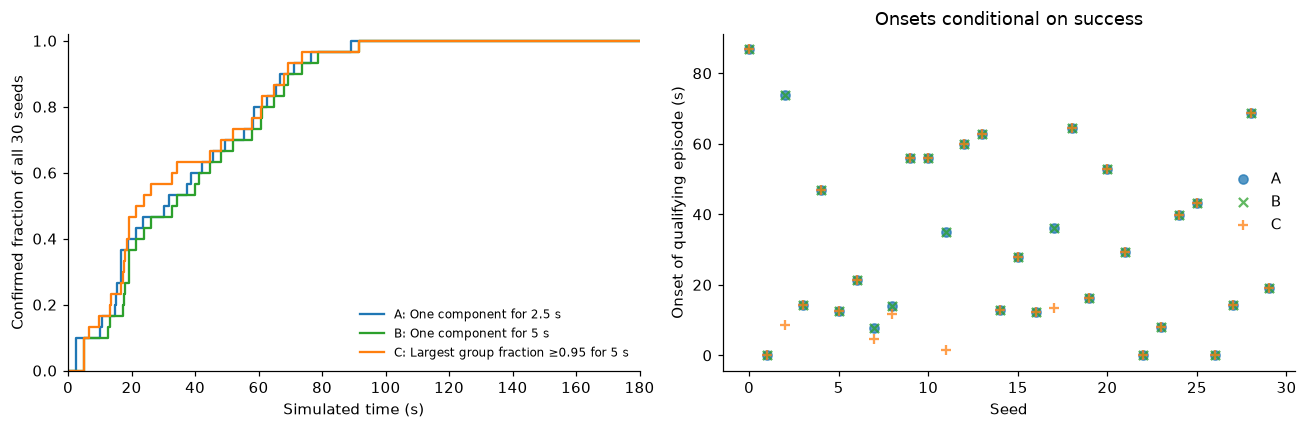

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = {"A": "tab:blue", "B": "tab:green", "C": "tab:orange"}
for key, definition in DEFINITIONS.items():
    successful = per_seed[(per_seed["Definition"] == key) & per_seed["AssemblySuccess"]]
    event_times = np.sort(successful["AssemblyConfirmedTime"].to_numpy())
    x = np.r_[0., event_times, 180.]
    y = np.r_[0., np.arange(1, len(event_times) + 1) / len(summary), len(event_times) / len(summary)]
    axes[0].step(x, y, where="post", label=key + ": " + definition["label"], color=colors[key])
    axes[1].scatter(successful["Seed"], successful["AssemblyTime"], label=key,
                    color=colors[key], alpha=.75, marker={"A": "o", "B": "x", "C": "+"}[key])
axes[0].set(xlabel="Simulated time (s)", ylabel="Confirmed fraction of all 30 seeds", ylim=(0, 1.02), xlim=(0, 180))
axes[0].legend(frameon=False, fontsize=8)
axes[1].set(xlabel="Seed", ylabel="Onset of qualifying episode (s)", title="Onsets conditional on success")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_definition_sensitivity.png", bbox_inches="tight")
plt.show()

## Recommendation and meaning

A useful future checkpoint rule should be clear, require the whole population to participate, and provide enough connected follow-up to reject an instantaneous encounter. Five seconds is a transparent practical convention; these data cannot establish a universal biologically correct duration. If B excludes many A successes or repeatedly loses connectivity after confirmation, that limitation must be reported rather than concealed by weakening the rule.

The generated recommendation reports the actual agreement and post-confirmation behaviour. C remains an informative sensitivity analysis, but it addresses **almost all fish**, a different question from complete assembly. A strict B checkpoint still needs notebook 04's reconstruction test and notebook 02's timestep assessment before use in a light experiment.

In [4]:
n_AB = int(different_AB.sum())
n_BC = int(different_BC.sum())
n_shift_AB = int(onset_changed_AB.sum())
n_shift_BC = int(onset_changed_BC.sum())
n_B = int(summary["B_AssemblySuccess"].sum())
n_breakup = int(summary.loc[summary["B_AssemblySuccess"], "PostAssemblyBreakup"].sum())
stable_observed = n_B > 0 and n_breakup == 0
robust_to_shorter_window = n_AB == 0 and n_shift_AB == 0
recommend_B = stable_observed and robust_to_shorter_window
recommendation = {
    "preferred_definition": "B" if recommend_B else "B_provisional_requires_review",
    "connectivity_radius_BL": 5.5,
    "required_number_of_components": 1,
    "persistence_s": 5.0,
    "monitor_every_internal_update": True,
    "assembly_time_means": "first observed time of the first episode that later meets persistence",
    "checkpoint_time_means": "first confirmation, onset + persistence",
    "biological_constant": False,
    "n_seeds": int(len(summary)),
    "duration_s": 180.0,
    "A_B_success_disagreements": n_AB,
    "A_B_onset_disagreements_among_both_successful": n_shift_AB,
    "B_C_success_disagreements": n_BC,
    "B_C_onset_disagreements_among_both_successful": n_shift_BC,
    "B_successes": n_B,
    "B_runs_with_later_breakup": n_breakup,
    "B_supported_in_tested_cohort": bool(recommend_B),
    "limitation": "Finite seeds and horizon; sampled graph connectivity is not biological school validation.",
}
(DATA_DIR / "03_assembly_definition.json").write_text(json.dumps(recommendation, indent=2) + "\n")
verdict = ("**Choose B for the checkpoint protocol in the tested reference cohort.**"
           if recommend_B else "**Keep B provisional and review the observed sensitivity before final checkpoint selection.**")
display(Markdown(
    f"**Executed sensitivity.** A versus B changes **{n_AB}/30** success labels and **{n_shift_AB}** "
    f"successful onset times. B versus C changes **{n_BC}/30** labels and **{n_shift_BC}** onset times "
    f"among runs successful under both conventions. B confirms **{n_B}/30**, with **{n_breakup}/{n_B}** "
    f"showing any subsequent disconnected update.\n\n{verdict} "
    "The stricter 5-s window is easy to explain, requires all 20 fish and avoids treating 19+1 as complete assembly. "
    "Its suitability is an observed property of this finite cohort, not proof of permanent stability or a calibrated "
    "biological threshold. Confirmation times are later than onsets by the specified persistence window."
))

**Executed sensitivity.** A versus B changes **0/30** success labels and **0** successful onset times. B versus C changes **0/30** labels and **5** onset times among runs successful under both conventions. B confirms **30/30**, with **0/30** showing any subsequent disconnected update.

**Choose B for the checkpoint protocol in the tested reference cohort.** The stricter 5-s window is easy to explain, requires all 20 fish and avoids treating 19+1 as complete assembly. Its suitability is an observed property of this finite cohort, not proof of permanent stability or a calibrated biological threshold. Confirmation times are later than onsets by the specified persistence window.